<a href="https://colab.research.google.com/github/bdipesh3045/Data-Science-project-AI-Class-/blob/main/palden/palden_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
%pip install -q kagglehub wandb tensorflow scikit-learn matplotlib

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import wandb
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

PROJECT = "sign-language-mnist"
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: []


In [36]:
wandb.login()

True

In [37]:
path = kagglehub.dataset_download("datamunge/sign-language-mnist")
train_df = pd.read_csv(glob.glob(os.path.join(path, "**", "sign_mnist_train.csv"), recursive=True)[0])
test_df  = pd.read_csv(glob.glob(os.path.join(path, "**", "sign_mnist_test.csv"),  recursive=True)[0])

X_train = train_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
y_train = train_df["label"].to_numpy()
X_test  = test_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
y_test  = test_df["label"].to_numpy()

labels  = sorted(np.unique(y_train))
letters = [chr(65 + int(l)) for l in labels]
print("Train:", X_train.shape, "| Test:", X_test.shape)

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
Train: (27455, 784) | Test: (7172, 784)


In [38]:
keras.utils.set_random_seed(42)   # makes results repeatable

def make_model(hidden_layers, activation, lr, dropout=0.0):
    model = keras.Sequential([keras.Input(shape=(784,))])
    for h in hidden_layers:
        model.add(layers.Dense(h, activation=activation))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(25, activation="softmax"))   # labels go 0–24
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

make_model([512, 256, 128], "relu", 1e-3, dropout=0.3).summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 569,369 (2.17 MB)

 Trainable params: 569,369 (2.17 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# Sends loss and accuracy to W&B at the end of every epoch
class WandbLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        wandb.log({"epoch": epoch + 1,
                   "train_loss": logs["loss"],
                   "test_loss": logs["val_loss"],
                   "test_acc": logs["val_accuracy"]})

In [40]:
def run_experiment(name, hidden_layers, activation, lr=1e-3, epochs=20, dropout=0.0):
    wandb.init(project=PROJECT, name=name,
               config={"model": "MLP (TensorFlow)", "hidden_layers": hidden_layers,
                       "activation": activation, "learning_rate": lr,
                       "dropout": dropout, "epochs": epochs, "batch_size": 128})

    model = make_model(hidden_layers, activation, lr, dropout)
    history = model.fit(X_train, y_train,
                        validation_data=(X_test, y_test),
                        epochs=epochs, batch_size=128,
                        callbacks=[WandbLogger()], verbose=0)

    test_acc = history.history["val_accuracy"][-1]
    wandb.finish()
    print(f"{name}: test accuracy {test_acc:.2%}")
    return model, test_acc

In [41]:
experiments = [
    # name                       layers             activation  learning rate
    ("mlp-3layer-relu",          [512, 256, 128],   "relu",     1e-3),
    ("mlp-3layer-tanh",          [512, 256, 128],   "tanh",     1e-3),
    ("mlp-3layer-sigmoid",       [512, 256, 128],   "sigmoid",  1e-3),
    ("mlp-3layer-relu-small",    [128, 64, 32],     "relu",     1e-3),
    ("mlp-3layer-relu-large",    [1024, 512, 256],  "relu",     1e-3),
    ("mlp-3layer-relu-lr0.01",   [512, 256, 128],   "relu",     1e-2),
    ("mlp-3layer-relu-lr0.0001", [512, 256, 128],   "relu",     1e-4),
]

results = {}
for name, hidden, act, lr in experiments:
    model, acc = run_experiment(name, hidden, act, lr=lr)
    results[name] = {"model": model, "acc": acc, "hidden": hidden, "act": act, "lr": lr}

print("\nSummary:")
for name, r in sorted(results.items(), key=lambda x: -x[1]["acc"]):
    print(f"  {name:28s} {r['acc']:.2%}")

epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
test_acc,▁▃▄▅▅▆▇▇███▇████████
test_loss,█▄▂▂▃▃▁▁▁▂▂▃▁▂▂▃▃▃▄▄
train_loss,█▄▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,20
test_acc,0.78555
test_loss,1.245
train_loss,0.00136


mlp-3layer-relu: test accuracy 78.56%


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
test_acc,▁▄▅▆▆▇██████████████
test_loss,█▄▃▂▃▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂
train_loss,█▄▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,20
test_acc,0.83575
test_loss,0.75995
train_loss,0.00097


mlp-3layer-tanh: test accuracy 83.58%


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
test_acc,▁▄▅▅▆▆▆▇▇▇▇█████████
test_loss,█▅▃▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss,█▅▄▄▃▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁
epoch,20
test_acc,0.77133
test_loss,0.96778
train_loss,0.01442


...

mlp-3layer-relu-large: test accuracy 82.00%


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
test_acc,▁▄▅▄▅▇▇▇▇▇▇▆█▆█▇▅▇██
test_loss,▄▂▁▄▂▂▂▂▄▅▄▄▅▄▅▆██▆▆
train_loss,█▅▄▃▂▂▂▂▂▂▂▂▁▂▁▁▂▂▁▁
epoch,20
test_acc,0.73898
test_loss,2.46443
train_loss,0.00494


mlp-3layer-relu-lr0.01: test accuracy 73.90%


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
test_acc,▁▃▄▅▆▆▆▇▇▇▇▇▇███████
test_loss,█▆▄▄▃▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁
train_loss,█▆▅▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁
epoch,20
test_acc,0.76255
test_loss,0.87257
train_loss,0.10269


mlp-3layer-relu-lr0.0001: test accuracy 76.25%

Summary:
  mlp-3layer-tanh              83.58%
  mlp-3layer-relu-large        82.00%
  mlp-3layer-relu              78.56%
  mlp-3layer-sigmoid           77.13%
  mlp-3layer-relu-lr0.0001     76.25%
  mlp-3layer-relu-lr0.01       73.90%
  mlp-3layer-relu-small        72.66%


In [42]:
extra = [
    ("mlp-3layer-relu-large-drop0.3", [1024, 512, 256], "relu", 1e-3, 0.3),
    ("mlp-3layer-relu-large-drop0.5", [1024, 512, 256], "relu", 1e-3, 0.5),
    ("mlp-3layer-tanh-drop0.3",       [512, 256, 128],  "tanh", 1e-3, 0.3),
]
for name, hidden, act, lr, drop in extra:
    model, acc = run_experiment(name, hidden, act, lr=lr, dropout=drop)
    results[name] = {"model": model, "acc": acc, "hidden": hidden, "act": act, "lr": lr}

print("\nFull summary:")
for name, r in sorted(results.items(), key=lambda x: -x[1]["acc"]):
    print(f"  {name:32s} {r['acc']:.2%}")

epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
test_acc,▁▃▄▅▅▆▆▇▆▇▇██████▇██
test_loss,█▅▅▃▃▂▂▂▂▂▂▂▁▁▂▁▁▂▁▁
train_loss,█▅▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
epoch,20
test_acc,0.78737
test_loss,0.68396
train_loss,0.35014


mlp-3layer-relu-large-drop0.3: test accuracy 78.74%


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
test_acc,▁▄▅▇▆▇███████▇██████
test_loss,█▅▃▃▃▂▂▂▁▁▂▁▁▁▂▁▂▁▁▂
train_loss,█▅▄▃▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁
epoch,20
test_acc,0.48355
test_loss,1.56928
train_loss,1.46922


mlp-3layer-relu-large-drop0.5: test accuracy 48.35%


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
test_acc,▁▃▄▅▅▆▆▆▆▇▇▇▇█▇▇▇██▇
test_loss,█▅▄▃▂▁▂▂▂▂▁▂▁▂▂▂▂▂▂▂
train_loss,█▅▄▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
epoch,20
test_acc,0.79253
test_loss,0.93341
train_loss,0.13706


mlp-3layer-tanh-drop0.3: test accuracy 79.25%

Full summary:
  mlp-3layer-tanh                  83.58%
  mlp-3layer-relu-large            82.00%
  mlp-3layer-tanh-drop0.3          79.25%
  mlp-3layer-relu-large-drop0.3    78.74%
  mlp-3layer-relu                  78.56%
  mlp-3layer-sigmoid               77.13%
  mlp-3layer-relu-lr0.0001         76.25%
  mlp-3layer-relu-lr0.01           73.90%
  mlp-3layer-relu-small            72.66%
  mlp-3layer-relu-large-drop0.5    48.35%


Best model: mlp-3layer-tanh
Test accuracy: 83.58%
Macro F1:      0.8175


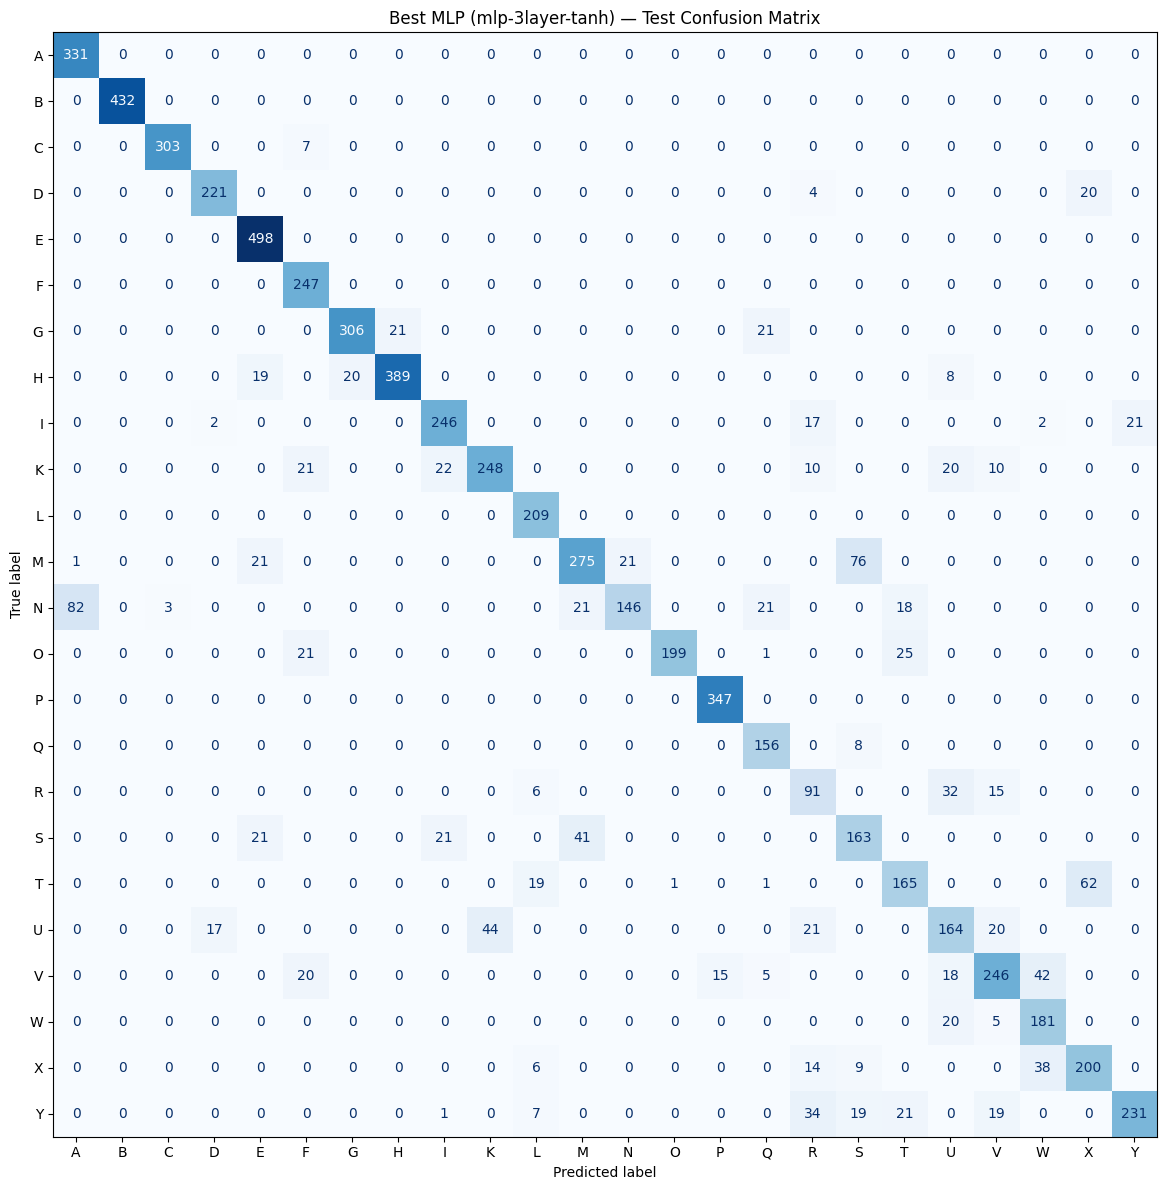

In [43]:
best_name = max(results, key=lambda k: results[k]["acc"])
best = results[best_name]
print("Best model:", best_name)

y_pred = best["model"].predict(X_test, verbose=0).argmax(axis=1)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2%}")
print(f"Macro F1:      {f1_score(y_test, y_pred, average='macro'):.4f}")

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=labels,
                                        display_labels=letters, cmap="Blues",
                                        colorbar=False, ax=ax)
ax.set_title(f"Best MLP ({best_name}) — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [44]:
best["model"].save("best_mlp.keras")

from google.colab import files
files.download("best_mlp.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>